In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler,MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [ ]:
import os
path = "/content/Wednesday-workingHours.pcap_ISCX.csv"
print(os.path.getsize(path) / 1e6, "MB")

225.166395 MB


In [ ]:
with open(path, "rb") as f:
    print(sum(1 for _ in f))

692704


In [ ]:
import pandas as pd

df_raw = pd.read_csv(path)
print(df_raw.shape)

(692703, 79)


In [ ]:
df_raw[' Label'].value_counts()

,count
Label,
BENIGN,440031
DoS Hulk,231073
DoS GoldenEye,10293
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11


missing values handling

In [ ]:
df_raw.head(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
df_raw.isnull().sum().sum()

np.int64(1008)

In [ ]:
df_cleaned = df_raw.dropna()  # Drop rows with NaN values
df_cleaned = df_cleaned[~df_cleaned.isin([np.inf, -np.inf]).any(axis=1)] # Drop rows with out of range values

In [ ]:
data = df_cleaned.iloc[:,:-1]   # data contains clean attributes
labels = df_cleaned.iloc[:,-1]  # labels contain the corresponding labels in categorical format ('BENIGN','DoS slowloris',... )

In [ ]:
# identifying zero-variance features
zero_variance_features = data.var() == 0
zero_variance_index = zero_variance_features[zero_variance_features].index
print("Features with zero variance:\n", zero_variance_index)

Features with zero variance:
 Index([' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' CWE Flag Count',
       'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate',
       ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'],
      dtype='object')


In [ ]:
# Droping the specified columns (i.e., those with zero variance)
data_dropped_zero_var = data.drop(columns= zero_variance_index)

In [ ]:
# Finding identical columns
columns = data_dropped_zero_var.columns
identical_columns = []

for col1 in data_dropped_zero_var.columns:
    for col2 in data_dropped_zero_var.columns:
        if col1 != col2 and data_dropped_zero_var[col1].equals(data_dropped_zero_var[col2]):
            identical_columns.append((col1, col2))

print("Identical columns:", identical_columns)

Identical columns: [(' Total Fwd Packets', 'Subflow Fwd Packets'), (' Total Backward Packets', ' Subflow Bwd Packets'), ('Total Length of Fwd Packets', ' Subflow Fwd Bytes'), (' Fwd Packet Length Mean', ' Avg Fwd Segment Size'), ('Fwd PSH Flags', ' SYN Flag Count'), (' Fwd Header Length', ' Fwd Header Length.1'), (' SYN Flag Count', 'Fwd PSH Flags'), (' Avg Fwd Segment Size', ' Fwd Packet Length Mean'), (' Fwd Header Length.1', ' Fwd Header Length'), ('Subflow Fwd Packets', ' Total Fwd Packets'), (' Subflow Fwd Bytes', 'Total Length of Fwd Packets'), (' Subflow Bwd Packets', ' Total Backward Packets')]


In [ ]:
# Use a set to filter out tuples considering (X, Y) and (Y, X) as the same
unique_pairs = set()

# Add each tuple to the set in a sorted order (to avoid duplicates with reversed order)
for pair in identical_columns:
    unique_pairs.add(tuple(sorted(pair)))

# Convert back to list to maintain the same structure as original input
unique_tuples_list = list(unique_pairs)

# Output the result
print(unique_tuples_list)

[(' Subflow Bwd Packets', ' Total Backward Packets'), (' SYN Flag Count', 'Fwd PSH Flags'), (' Avg Fwd Segment Size', ' Fwd Packet Length Mean'), (' Subflow Fwd Bytes', 'Total Length of Fwd Packets'), (' Fwd Header Length', ' Fwd Header Length.1'), (' Total Fwd Packets', 'Subflow Fwd Packets')]


In [ ]:
 #Extract the columns to drop (second item of each tuple)
columns_to_drop = [pair[1] for pair in unique_tuples_list]

In [ ]:
# Drop the duplicate columns from the DataFrame
data_var_ident_dropped = data_dropped_zero_var.drop(columns=columns_to_drop)

In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_var_ident_dropped)  # it converts pandas dataframe into a numpy array


In [ ]:
cov_matrix = np.cov(scaled_data, rowvar=False)

covariance

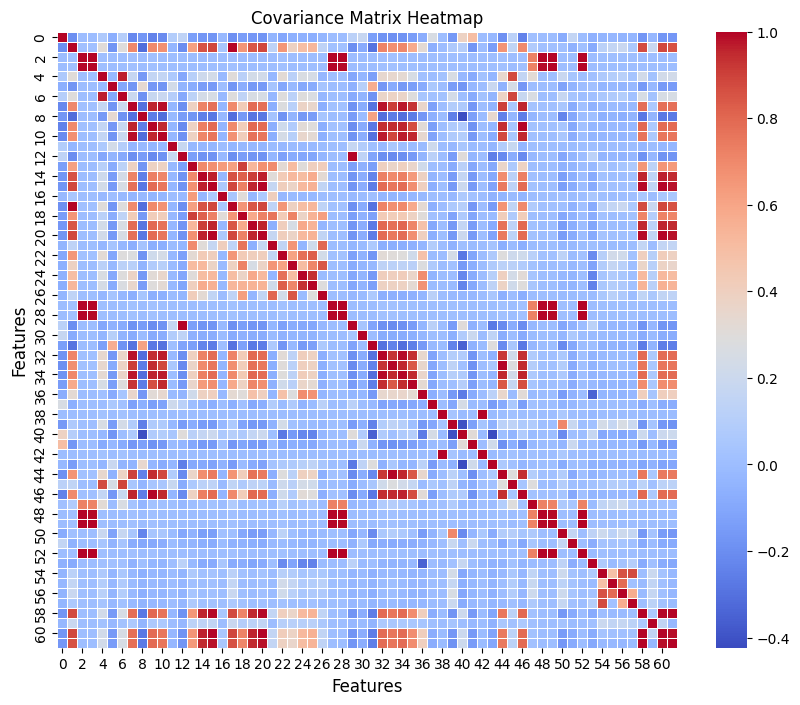

In [ ]:
plt.figure(figsize=(10, 8))

# Create the heatmap using seaborn
sns.heatmap(cov_matrix, annot=False, cmap="coolwarm", fmt='.2f', linewidths=0.5)

# Add labels and title
plt.title('Covariance Matrix Heatmap', fontsize=12)
plt.xlabel('Features', fontsize=12)
plt.ylabel('Features', fontsize=12)

# Show the plot
plt.show()

In [ ]:
# Convert categorical labels to numerical values
labels_numeric = labels.apply(lambda x: 0 if x == 'BENIGN' else 1)

In [ ]:
data_var_ident_dropped.head(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,80,38308,1,6,6,6,0.000000,6,6,6.000000,...,0,20,0.0,0.0,0,0,0.0,0.0,0,0
1,389,479,11,326,79,0,31.449238,163,0,65.200000,...,4,32,0.0,0.0,0,0,0.0,0.0,0,0
2,88,1095,10,3150,1575,0,632.561635,1575,0,525.000000,...,3,32,0.0,0.0,0,0,0.0,0.0,0,0
3,389,15206,17,6660,1313,0,425.778474,3069,0,555.000000,...,10,32,0.0,0.0,0,0,0.0,0.0,0,0
4,88,1092,9,3152,1575,0,694.509719,1576,0,525.333333,...,2,32,0.0,0.0,0,0,0.0,0.0,0,0


In [ ]:
# Concatenate labels with cleaned data
cleaned_data_labels = pd.concat([data_var_ident_dropped, labels_numeric.rename('Label')], axis=1)

In [ ]:
X = cleaned_data_labels.iloc[:, :-1]  # features: all columns except the last one
y = cleaned_data_labels.iloc[:, -1]   # targets : last column

In [ ]:
# Split the data into training and validation sets.
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
y_valid.shape

(207422,)

In [ ]:
##### scratch implementation
def sigmoid(z): return 1 / (1 + np.exp(-z))

def logloss(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

In [ ]:
from sklearn.tree import DecisionTreeRegressor

class BoostedTree:

    def __init__(self, max_depth, reg_lambda, gamma, min_child_weight):
        self.max_depth, self.lam, self.gamma, self.mcw = max_depth, reg_lambda, gamma, min_child_weight

    def fit(self, Xb, g, h, edges, eta):
        # minimum hessian weight per leaf, expressed as a fraction of the total weight
        frac = min(self.mcw / h.sum(), 0.5)
        self.skl = DecisionTreeRegressor(max_depth=self.max_depth, min_weight_fraction_leaf=frac, random_state=0)
        self.skl.fit(Xb, -g / h, sample_weight=h)
        t = self.skl.tree_
        n, left, right, feat = t.node_count, t.children_left, t.children_right, t.feature

        #  XGBoost statistics G, H of every node
        leaf_of = self.skl.apply(Xb)
        G = np.bincount(leaf_of, weights=g, minlength=n)
        H = np.bincount(leaf_of, weights=h, minlength=n)
        for i in range(n - 1, -1, -1):
            if left[i] != -1:
                G[i], H[i] = G[left[i]] + G[right[i]], H[left[i]] + H[right[i]]

        # split gain and leaf weights
        score = lambda g_, h_: g_**2 / (h_ + self.lam)
        internal = left != -1
        gain = np.zeros(n)
        gain[internal] = 0.5 * (score(G[left[internal]], H[left[internal]]) +
                                score(G[right[internal]], H[right[internal]]) -
                                score(G[internal], H[internal])) - self.gamma
        value = -G / (H + self.lam) * eta

        # gamma pruning (bottom-up), a split with gain <= 0 whose children are leaves is removed
        is_leaf = ~internal
        for i in range(n - 1, -1, -1):
            if not is_leaf[i] and is_leaf[left[i]] and is_leaf[right[i]] and gain[i] <= 0:
                is_leaf[i] = True
        pred_value = value.copy()                             # value of the leaf a sample ends in after pruning
        collapsed = np.zeros(n, dtype=bool)
        for i in range(n):                                    # parents come before children
            if internal[i] and (is_leaf[i] or collapsed[i]):
                for c in (left[i], right[i]):
                    collapsed[c], pred_value[c] = True, pred_value[i]

        # final tree arrays (feature = -1 means leaf); thresholds converted back to raw feature units
        keep = internal & ~is_leaf & ~collapsed
        self.feature = np.where(keep, feat, -1)
        self.left    = np.where(keep, left, -1)
        self.right   = np.where(keep, right, -1)
        self.thr     = np.zeros(n)
        for i in np.flatnonzero(keep):                        # split "bin <= k"  <=>  "x <= edges[k]"
            self.thr[i] = edges[feat[i]][int(t.threshold[i])]
        self.value, self.pred_value = value, pred_value
        self.stats = [(feat[i], gain[i], H[i]) for i in np.flatnonzero(keep)]
        return self

    def predict(self, Xb):
        return self.pred_value[self.skl.apply(Xb)]

In [ ]:
class SimpleXGBoost:
    def __init__(self, max_depth=4, eta=0.1, reg_lambda=1.0, gamma=0.0,
                 min_child_weight=1.0, n_bins=256):
        self.max_depth, self.eta, self.reg_lambda = max_depth, eta, reg_lambda
        self.gamma, self.mcw, self.n_bins = gamma, min_child_weight, n_bins

    def _bin(self, X):
        """Map raw features to quantile-bin indices (float32, which is what sklearn trees work on)."""
        Xv = X.values.astype(float)
        return np.column_stack([np.searchsorted(self.edges[j], Xv[:, j], side="left")
                                for j in range(Xv.shape[1])]).astype(np.float32)

    def fit(self, X, y, X_valid, y_valid, num_rounds=50, early_stopping_rounds=10):
        self.columns = list(X.columns)
        Xv, yv = X.values.astype(float), y.values.astype(float)
        yval = y_valid.values.astype(float)

        # bin every feature once (quantile bins)
        q = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges = [np.unique(np.quantile(Xv[:, j], q)) for j in range(Xv.shape[1])]
        Xb, Xbval = self._bin(X), self._bin(X_valid)

        p0 = yv.mean()
        self.base = np.log(p0 / (1 - p0))                      # starting prediction (log-odds)
        F, Fval = np.full(len(yv), self.base), np.full(len(yval), self.base)
        self.trees, self.history = [], {"train": [], "eval": []}
        best, best_round = np.inf, 0

        for r in range(num_rounds):
            p = np.clip(sigmoid(F), 1e-6, 1 - 1e-6)            # clip keeps the hessian away from 0
            g, h = p - yv, p * (1 - p)                         # gradient, hessian of logloss
            t = BoostedTree(self.max_depth, self.reg_lambda, self.gamma, self.mcw).fit(Xb, g, h, self.edges, self.eta)
            self.trees.append(t)
            F += t.predict(Xb)
            Fval += t.predict(Xbval)

            tr, ev = logloss(yv, sigmoid(F)), logloss(yval, sigmoid(Fval))
            self.history["train"].append(tr); self.history["eval"].append(ev)
            print(f"[{r}] train-logloss:{tr:.5f} eval-logloss:{ev:.5f}")

            if ev < best: best, best_round = ev, r
            elif r - best_round >= early_stopping_rounds:
                print("early stopping at round", r); break
        self.trees = self.trees[:best_round + 1]               # keep best iteration
        return self

    def predict_proba(self, X):
        Xb = self._bin(X)
        F = np.full(len(Xb), self.base)
        for t in self.trees: F += t.predict(Xb)
        return sigmoid(F)

    def importance(self):
        rows = [(self.columns[f], gain, cover) for t in self.trees for f, gain, cover in t.stats]
        df = pd.DataFrame(rows, columns=["feat", "gain", "cover"])
        out = df.groupby("feat").agg(gain=("gain", "mean"),     # average gain per split
                                     cover=("cover", "mean"),   # average hessian at split
                                     weight=("gain", "size"))   # number of splits
        return out.reindex(self.columns).fillna(0)

In [ ]:
model = SimpleXGBoost(max_depth=4, eta=0.1)
model.fit(X_train, y_train, X_valid, y_valid, num_rounds=50, early_stopping_rounds=10)

[0] train-logloss:0.56634 eval-logloss:0.56648
[1] train-logloss:0.49530 eval-logloss:0.49545
[2] train-logloss:0.43711 eval-logloss:0.43726
[3] train-logloss:0.38852 eval-logloss:0.38869
[4] train-logloss:0.34740 eval-logloss:0.34757
[5] train-logloss:0.30961 eval-logloss:0.30979
[6] train-logloss:0.27711 eval-logloss:0.27728
[7] train-logloss:0.24897 eval-logloss:0.24914
[8] train-logloss:0.22444 eval-logloss:0.22459
[9] train-logloss:0.20297 eval-logloss:0.20313
[10] train-logloss:0.18411 eval-logloss:0.18425
[11] train-logloss:0.16747 eval-logloss:0.16761
[12] train-logloss:0.15278 eval-logloss:0.15292
[13] train-logloss:0.13956 eval-logloss:0.13967
[14] train-logloss:0.12800 eval-logloss:0.12811
[15] train-logloss:0.11758 eval-logloss:0.11775
[16] train-logloss:0.10830 eval-logloss:0.10844
[17] train-logloss:0.09984 eval-logloss:0.10001
[18] train-logloss:0.09242 eval-logloss:0.09263
[19] train-logloss:0.08567 eval-logloss:0.08592
[20] train-logloss:0.07970 eval-logloss:0.07997
[2

In [ ]:
importance_df = model.importance()

# min-max normalise each column to [0,1] (replaces MinMaxScaler)
importance_df = (importance_df - importance_df.min()) / (importance_df.max() - importance_df.min())
importance_df = importance_df.sort_values(by='gain', ascending=False)

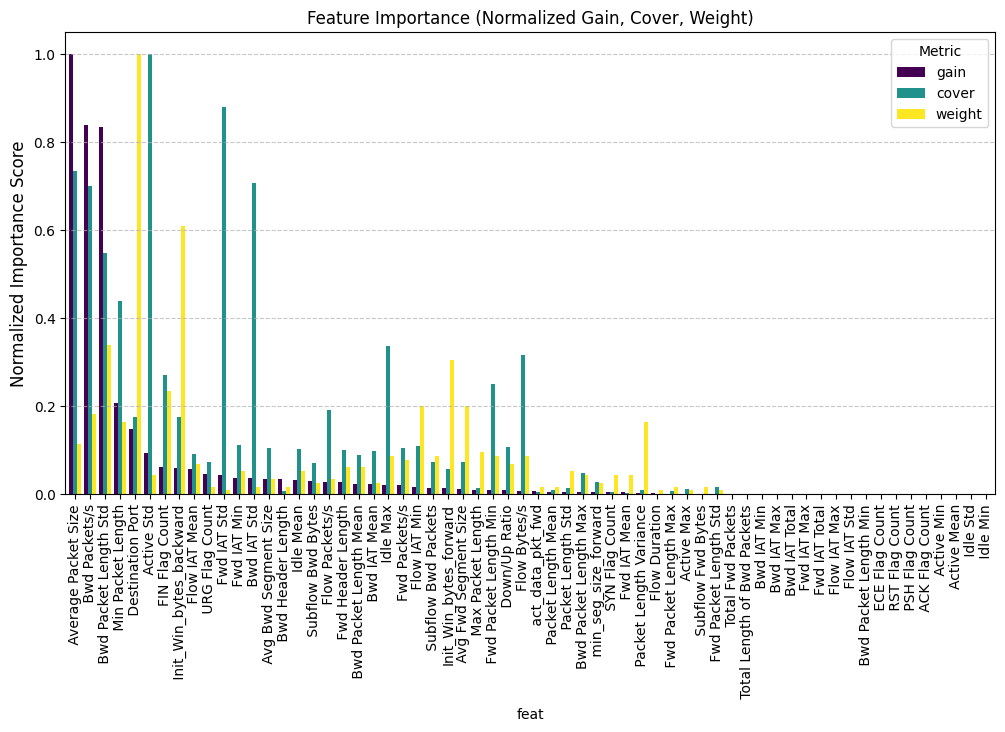

In [ ]:
# Plot Feature Importance
importance_df.plot(kind='bar', figsize=(12, 6), width=0.8, colormap='viridis')
#plt.xlabel('Features',fontsize=14)
plt.ylabel('Normalized Importance Score',fontsize=12)
plt.title('Feature Importance (Normalized Gain, Cover, Weight)')
plt.legend(title='Metric')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

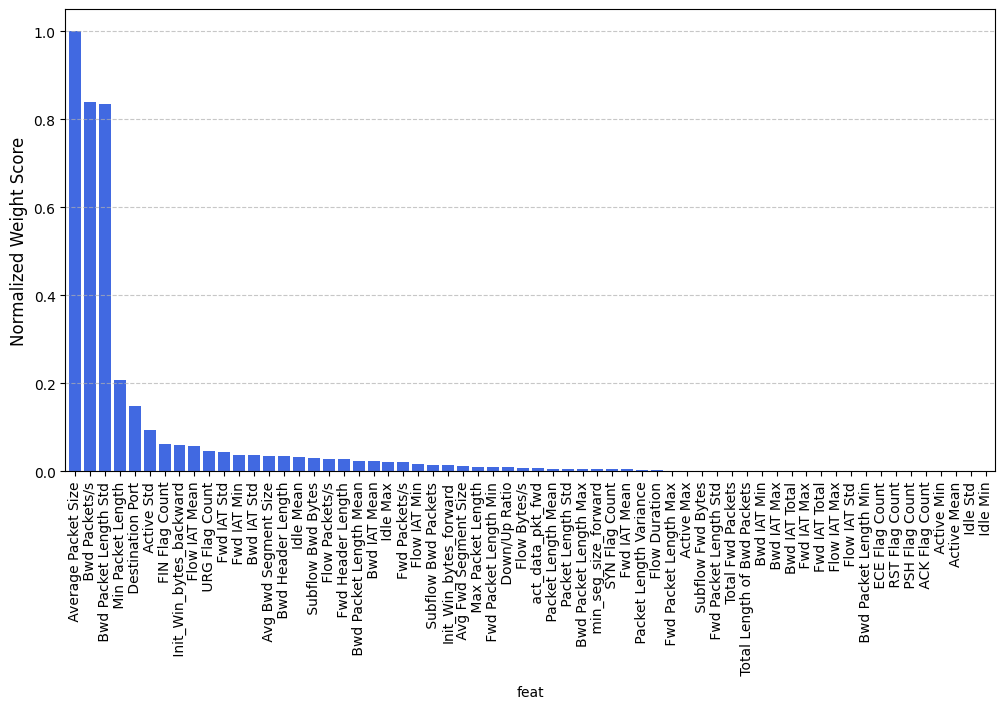

In [ ]:
# Plot Gain Scores
plt.figure(figsize=(12, 6))
importance_df['gain'].plot(kind='bar', color='royalblue', width=0.8)

#plt.xlabel('Features', fontsize=14)
plt.ylabel('Normalized Weight Score', fontsize=12)
# plt.title('Feature Importance (Gain Only)', fontsize=14)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [ ]:
importance_df

,gain,cover,weight
feat,,,
Average Packet Size,1.000000,0.733491,0.113043
Bwd Packets/s,0.838792,0.699707,0.182609
Bwd Packet Length Std,0.833721,0.547216,0.339130
Min Packet Length,0.207089,0.439413,0.165217
Destination Port,0.147228,0.175210,1.000000
...,...,...,...
ACK Flag Count,0.000000,0.000000,0.000000
Active Min,0.000000,0.000000,0.000000
Active Mean,0.000000,0.000000,0.000000


In [ ]:
y_pred_proba = model.predict_proba(X_valid)
y_pred = (y_pred_proba >= 0.5).astype(int)
y_true = y_valid.values

TP = np.sum((y_pred == 1) & (y_true == 1))
FP = np.sum((y_pred == 1) & (y_true == 0))
FN = np.sum((y_pred == 0) & (y_true == 1))

accuracy  = np.mean(y_pred == y_true)
precision = TP / (TP + FP)
recall    = TP / (TP + FN)

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

Accuracy: 0.9970
Precision: 0.9938
Recall: 0.9980


proposed method, compress decision trees

In [ ]:
index_list = importance_df.index.tolist()

In [ ]:
# Sample the dataset randomly
N = 40000
SampledDataset = cleaned_data_labels.sample(n=N,random_state = 45)

In [ ]:
# Define features and target variable
X = SampledDataset.iloc[:, :-1]  # All columns except the last one as features
y = SampledDataset.iloc[:, -1]   # Last column as the target variable

In [ ]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier   # Decision Tree model
import joblib                                     # For saving the trained models

num_of_important_features = len(index_list)       # Get the number of important features from the provided index list

In [ ]:
# Split the dataset into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Initialize lists to store evaluation metrics and results
results = []
precision_list = []
recall_list = []
accuracy_list = []

In [ ]:
# Iterate through different numbers of important features
for feature_num in range(1,num_of_important_features):
    # Select a subset of features to include in training and testing
    columns_to_keep = index_list[0:feature_num]
    X_train_subset = X_train.loc[:,columns_to_keep]
    X_test_subset = X_test.loc[:,columns_to_keep]

    # Initialize and train a Decision Tree classifier with a max depth of 4
    model = DecisionTreeClassifier(random_state=42,max_depth=4)
    model.fit(X_train_subset, y_train)
    # # Make predictions on the test set
    y_pred = model.predict(X_test_subset)

    # Calculate evaluation metrics: precision, recall, and accuracy
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)

    # Store computed metrics in respective lists
    precision_list.append(precision)
    recall_list.append(recall)
    accuracy_list.append(accuracy)


   # Store the results for this feature subset
    results.append((feature_num, precision, recall, accuracy))
   # Save the trained model for this feature subset
    joblib.dump(model, f"decision_tree_{feature_num}.joblib")

In [ ]:
# Convert results list into a DataFrame for better readability and analysis
results_df = pd.DataFrame(results, columns=['Number of Features', 'Precision', 'Recall', 'Accuracy'])

In [ ]:
results_df

,Number of Features,Precision,Recall,Accuracy
0,1,0.816422,0.961326,0.907750
1,2,0.916170,0.954765,0.952000
2,3,0.944951,0.966160,0.967375
3,4,0.943733,0.967196,0.967250
4,5,0.989455,0.939572,0.974500
...,...,...,...,...
56,57,0.984440,0.983080,0.988250
57,58,0.984440,0.983080,0.988250
58,59,0.984440,0.983080,0.988250
59,60,0.984440,0.983080,0.988250


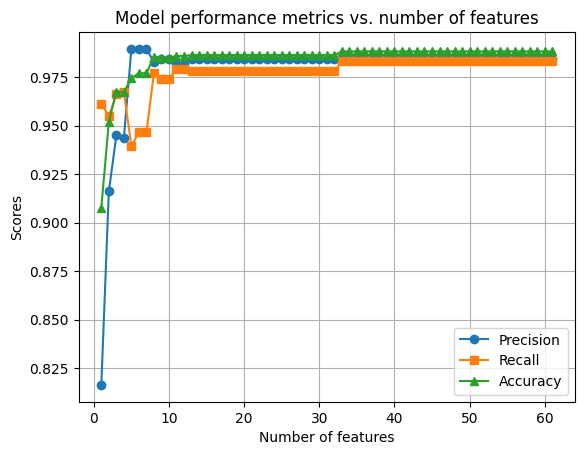

In [ ]:
# Performance metric curves
plt.plot(range(1, len(precision_list) + 1), precision_list, marker='o', label='Precision')
plt.plot(range(1, len(recall_list) + 1), recall_list, marker='s', label='Recall')
plt.plot(range(1, len(accuracy_list) + 1), accuracy_list, marker='^', label='Accuracy')

plt.xlabel('Number of features')
plt.ylabel('Scores')
plt.title('Model performance metrics vs. number of features')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.tree import export_graphviz
import graphviz
import joblib

# Select the number of features to visualize the relevent decision tree
feature_num = 8  # Change this value to visualize a model trained with a different number of features

# Load the trained Decision Tree model corresponding to the selected feature subset
model = joblib.load(f"decision_tree_{feature_num}.joblib")

# Get the corresponding feature names
columns_to_keep = index_list[:feature_num]

# Export tree as a DOT format string
dot_data = export_graphviz(model, out_file=None,
                           feature_names=columns_to_keep,
                           class_names=['Class 0', 'Class 1'],
                           filled=True, rounded=True, special_characters=True)

# Render and display the tree
graph = graphviz.Source(dot_data)
graph.render(f"decision_tree_{feature_num}")  # Saves as 'decision_tree_7.pdf' or other formats

'decision_tree_8.pdf'

## GlassBoost with max depth = 5

In [ ]:
# Same experiment as the depth-4 loop, but with max_depth = 5
# (uses the X_train / X_test split of the 40,000 sampled rows created above)
results_d5 = []
precision_list_d5 = []
recall_list_d5 = []
accuracy_list_d5 = []

for feature_num in range(1, num_of_important_features):
    columns_to_keep = index_list[0:feature_num]
    X_train_subset = X_train.loc[:, columns_to_keep]
    X_test_subset = X_test.loc[:, columns_to_keep]

    # Decision Tree with a max depth of 5
    model_d5 = DecisionTreeClassifier(random_state=42, max_depth=5)
    model_d5.fit(X_train_subset, y_train)
    y_pred = model_d5.predict(X_test_subset)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)

    precision_list_d5.append(precision)
    recall_list_d5.append(recall)
    accuracy_list_d5.append(accuracy)
    results_d5.append((feature_num, precision, recall, accuracy))

    # separate file name so the depth-4 models are not overwritten
    joblib.dump(model_d5, f"decision_tree_depth5_{feature_num}.joblib")

results_df_d5 = pd.DataFrame(results_d5, columns=['Number of Features', 'Precision', 'Recall', 'Accuracy'])

In [ ]:
results_df_d5

,Number of Features,Precision,Recall,Accuracy
0,1,0.820490,0.959599,0.909375
1,2,0.928405,0.962707,0.959625
2,3,0.949796,0.966851,0.969500
3,4,0.950441,0.966851,0.969750
4,5,0.991513,0.968232,0.985500
...,...,...,...,...
56,57,0.986197,0.986878,0.990250
57,58,0.986197,0.986878,0.990250
58,59,0.986197,0.986878,0.990250
59,60,0.986197,0.986878,0.990250


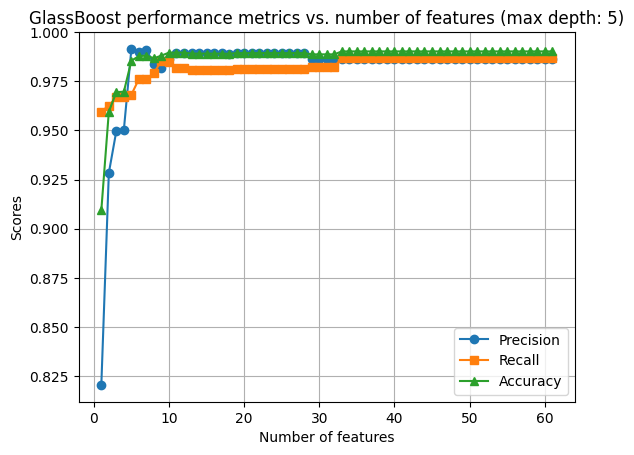

In [ ]:
# Performance metric curves (max depth = 5)
plt.plot(range(1, len(precision_list_d5) + 1), precision_list_d5, marker='o', label='Precision')
plt.plot(range(1, len(recall_list_d5) + 1), recall_list_d5, marker='s', label='Recall')
plt.plot(range(1, len(accuracy_list_d5) + 1), accuracy_list_d5, marker='^', label='Accuracy')

plt.xlabel('Number of features')
plt.ylabel('Scores')
plt.title('GlassBoost performance metrics vs. number of features (max depth: 5)')
plt.legend()
plt.grid(True)
plt.show()

### GlassBoost decision tree graph (max depth = 5, top 8 features)

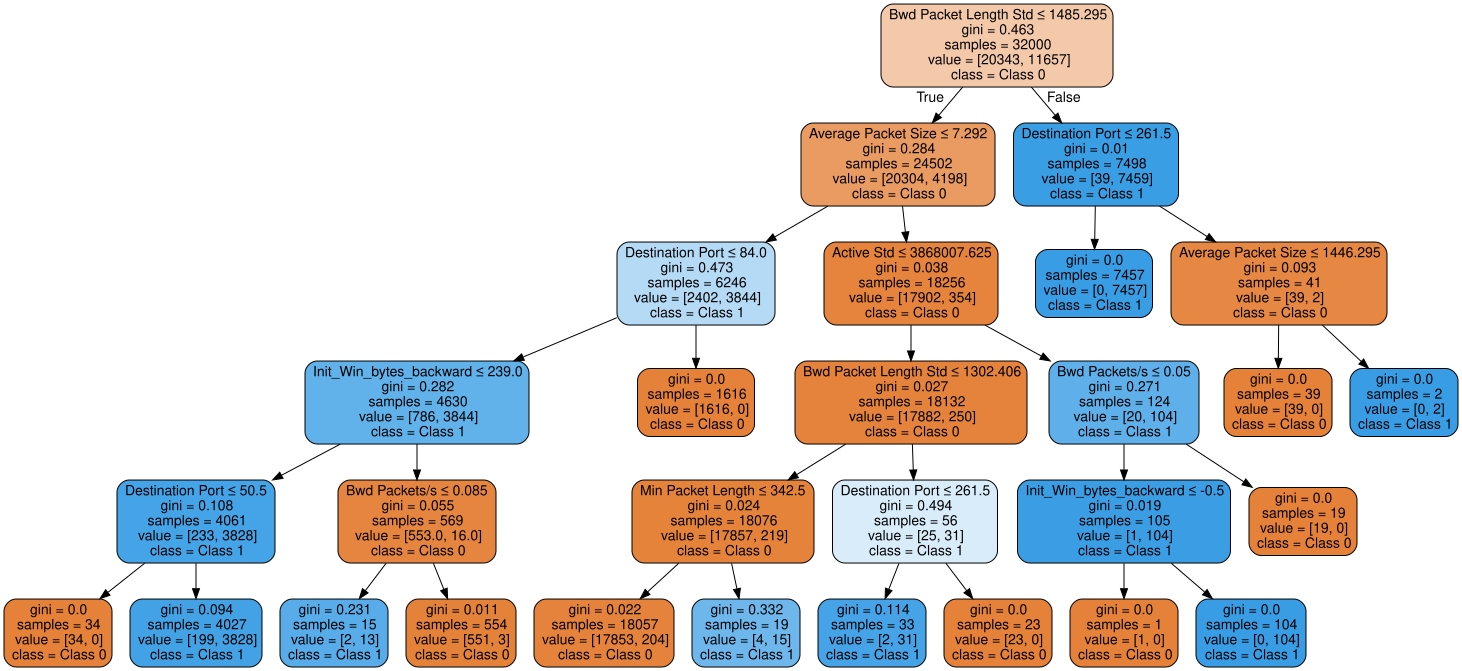

In [ ]:
from sklearn.tree import export_graphviz
import graphviz
import joblib

feature_num = 8   # number of top-gain features (the paper uses 8 for Figure 9)

# Load the depth-5 tree trained on the top `feature_num` features
model_d5 = joblib.load(f"decision_tree_depth5_{feature_num}.joblib")
columns_to_keep = index_list[:feature_num]

dot_data = export_graphviz(model_d5, out_file=None,
                           feature_names=columns_to_keep,
                           class_names=['Class 0', 'Class 1'],
                           filled=True, rounded=True, special_characters=True)

graph_d5 = graphviz.Source(dot_data)
graph_d5.render(f"decision_tree_depth5_{feature_num}", format="png", cleanup=True)  # saves the PNG
graph_d5

In [ ]:
print("Leaf nodes (= number of IF-THEN rules):", model_d5.get_n_leaves())

Leaf nodes (= number of IF-THEN rules): 15
